# Neural network #
Feed-forward network (PyTorch) on the same features and folds as `xgboost.ipynb`, evaluated walk-forward (rolling origin, expanding window): at the start of every month from September 2022 the network is retrained on all consumption known at that time and forecasts that month. The errors of all months are pooled, so the test covers autumn, winter and spring.

Hyperparameters are tuned once with Optuna on three 2-week windows inside the first fold's training data (mid-July to late August) and kept fixed afterwards, so no test month influences the choice of model. Each forecast is the mean of networks trained with different seeds.

Requires `pip install torch optuna`.

In [1]:
import time
import numpy as np
import pandas as pd
from pathlib import Path
import torch
from torch import nn
import optuna
from forecast_checks import LeakageChecker, ForecastValidator, MakeTrainingData

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

c:\Users\truls\anaconda3\envs\mlenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_DIR = Path("../data")
df = pd.read_csv(DATA_DIR / "dataset.csv", parse_dates=["date"])

In [3]:
#Same folds as xgboost.ipynb; MakeTrainingData reads the same CSV, so its row labels index df
#Walk forward: retrain at the start of every month and forecast that month. Helsingfors starts in mid-July,
#so September is the first month with Finnish training data
trainer = MakeTrainingData()
FIRST_TEST = "2022-09-01"
test_folds = [(df.loc[f["train"]["feature"].index], df.loc[f["test"]["feature"].index])
              for f in trainer.walk_forward(FIRST_TEST)]
for fit, test_part in test_folds:
    print(f"fit: {fit['date'].min().date()} - {fit['date'].max().date()}, test: {test_part['date'].min().date()} - {test_part['date'].max().date()}")

#Optuna tunes on three consecutive 2-week windows at the end of the first fold's training data, so no test month is used.
#Each window is trained on everything up to 6 days before it; several windows make the choice of model less dependent on one period
VAL_DAYS, N_WINDOWS = 14, 3
tune_end = test_folds[0][0]["date"].max()
val_windows = [(df.loc[f["train"]["feature"].index], df.loc[f["test"]["feature"].index])
               for f in trainer.walk_forward(tune_end - pd.Timedelta(days=VAL_DAYS * N_WINDOWS - 1),
                                             freq=f"{VAL_DAYS}D", until=tune_end)]
for fit, val in val_windows:
    print(f"tune fit: {fit['date'].min().date()} - {fit['date'].max().date()}, val: {val['date'].min().date()} - {val['date'].max().date()}")

fit: 2022-04-07 - 2022-08-26, test: 2022-09-01 - 2022-09-30
fit: 2022-04-07 - 2022-09-25, test: 2022-10-01 - 2022-10-31
fit: 2022-04-07 - 2022-10-26, test: 2022-11-01 - 2022-11-30
fit: 2022-04-07 - 2022-11-25, test: 2022-12-01 - 2022-12-31
fit: 2022-04-07 - 2022-12-26, test: 2023-01-01 - 2023-01-31
fit: 2022-04-07 - 2023-01-26, test: 2023-02-01 - 2023-02-28
fit: 2022-04-07 - 2023-02-23, test: 2023-03-01 - 2023-03-31
fit: 2022-04-07 - 2023-03-26, test: 2023-04-01 - 2023-04-03
tune fit: 2022-04-07 - 2022-07-10, val: 2022-07-16 - 2022-07-29
tune fit: 2022-04-07 - 2022-07-24, val: 2022-07-30 - 2022-08-12
tune fit: 2022-04-07 - 2022-08-07, val: 2022-08-13 - 2022-08-26


In [4]:
feats = ["location", "hour", "weekday", "temperature",
         "consumption_6days_ago", "consumption_7days_ago", "consumption_14days_ago",
         "max_consumption_last_available_day", "min_consumption_last_available_day"]
LeakageChecker.check_feature_names(feats)
LAG_FEATS = [f for f in feats if "consumption" in f]
LOCATIONS = sorted(df["location"].unique())


def drop_missing(fit, pred):
    """The network cannot take missing lags, so keep rows where every lag exists (same rows as the comparison in xgboost.ipynb).
    Prediction rows are also limited to locations the fit set has: the early tuning windows have no Helsingfors rows to fit on."""
    fit, pred = fit.dropna(subset=feats), pred.dropna(subset=feats)
    return fit, pred[pred["location"].isin(fit["location"].unique())]


test_folds = [drop_missing(fit, test_part) for fit, test_part in test_folds]
val_windows = [drop_missing(fit, val) for fit, val in val_windows]


class Scaler:
    """Scaling fitted on training data only: consumption relative to each location's mean, temperature standardized."""

    def __init__(self, data):
        #Oslo is about 6 times larger than Tromsø; relative consumption lets one network learn all locations
        self.level = data.groupby("location")["consumption"].mean()
        self.temp_mean, self.temp_std = data["temperature"].mean(), data["temperature"].std()

    def levels(self, data):
        return data["location"].map(self.level).to_numpy()

    def X(self, data):
        lags = data[LAG_FEATS].to_numpy() / self.levels(data)[:, None]
        temp = ((data["temperature"] - self.temp_mean) / self.temp_std).to_numpy()[:, None]
        onehot = [pd.get_dummies(pd.Categorical(data[col], categories=cats)).to_numpy()
                  for col, cats in (("location", LOCATIONS), ("hour", range(24)), ("weekday", range(7)))]
        return torch.tensor(np.hstack([lags, temp, *onehot]), dtype=torch.float32)

    def y(self, data):
        return torch.tensor(data["consumption"].to_numpy() / self.levels(data), dtype=torch.float32)

    def to_mw(self, data, pred):
        return pred * self.levels(data)

In [5]:
MAX_EPOCHS = 40
PATIENCE = 5
N_SEEDS = 5


class MLP(nn.Module):
    def __init__(self, n_inputs, hidden, n_layers, dropout):
        super().__init__()
        layers = []
        for i in range(n_layers):
            layers += [nn.Linear(n_inputs if i == 0 else hidden, hidden), nn.ReLU(), nn.Dropout(dropout)]
        self.net = nn.Sequential(*layers, nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(X).numpy()


def train_model(params, X, y, epochs, val=None, seed=SEED):
    """Train with L1 loss (= MAE). With val = (X_val, y_val in MW, scaler, val data), stop early and return the best epoch."""
    torch.manual_seed(seed)
    model = MLP(X.shape[1], params["hidden"], params["n_layers"], params["dropout"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    loss_fn = nn.L1Loss()
    best_mae, best_epoch = np.inf, 0
    for epoch in range(1, epochs + 1):
        model.train()
        #Shuffling rows is fine: every row already carries its own lag features
        for batch in torch.randperm(len(X)).split(params["batch_size"]):
            optimizer.zero_grad()
            loss_fn(model(X[batch]), y[batch]).backward()
            optimizer.step()
        if val is None:
            continue
        X_val, y_val, scaler, val_data = val
        mae = ForecastValidator.score(y_val, scaler.to_mw(val_data, predict(model, X_val)))["mae"]
        if mae < best_mae:
            best_mae, best_epoch = mae, epoch
        elif epoch - best_epoch >= PATIENCE:
            break
    return model, best_mae, best_epoch


def ensemble_forecast(params, epochs, fit_data, pred_data):
    """Mean forecast in MW of N_SEEDS networks that differ only in seed; averaging removes much of the seed-to-seed variance."""
    scaler = Scaler(fit_data)
    X, y, X_pred = scaler.X(fit_data), scaler.y(fit_data), scaler.X(pred_data)
    preds = [predict(train_model(params, X, y, epochs, seed=SEED + i)[0], X_pred) for i in range(N_SEEDS)]
    return scaler.to_mw(pred_data, np.mean(preds, axis=0))

In [6]:
#Tune on the validation windows; each window's scaler only sees its own fit period
fold_sets = []
for fit, val in val_windows:
    fit_scaler = Scaler(fit)
    fold_sets.append((fit_scaler.X(fit), fit_scaler.y(fit), (fit_scaler.X(val), val["consumption"], fit_scaler, val)))
N_TRIALS = 40


def objective(trial):
    params = {"n_layers": trial.suggest_int("n_layers", 1, 3),
              "hidden": trial.suggest_categorical("hidden", [32, 64, 128, 256]),
              "dropout": trial.suggest_float("dropout", 0.0, 0.3),
              "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
              "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
              "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024])}
    maes, epochs = [], []
    for step, (X_fit, y_fit, val_set) in enumerate(fold_sets):
        _, mae, best_epoch = train_model(params, X_fit, y_fit, MAX_EPOCHS, val=val_set)
        maes.append(mae)
        epochs.append(best_epoch)
        #Every trial sees the windows in the same order, so the running mean can be compared between trials
        trial.report(np.mean(maes), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("best_epoch", round(np.mean(epochs)))
    trial.set_user_attr("fold_maes", maes)
    return np.mean(maes)


start = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=0))
#Fixed number of trials, not a time budget: with a timeout the number of trials (and so the chosen model) depends on machine speed
study.optimize(objective, n_trials=N_TRIALS)
pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
print(f"{len(study.trials)} trials ({pruned} pruned) in {time.time() - start:.0f} s")
print("Best mean validation MAE:", study.best_value, "per window:", study.best_trial.user_attrs["fold_maes"],
      "at epoch", study.best_trial.user_attrs["best_epoch"])
study.best_params

40 trials (19 pruned) in 172 s
Best mean validation MAE: 0.12217995124648319 per window: [0.07588552037741905, 0.09732489873218388, 0.19332943462984664] at epoch 7


{'n_layers': 2,
 'hidden': 128,
 'dropout': 0.23463280321959798,
 'lr': 0.00323067461734994,
 'weight_decay': 3.948046165485038e-06,
 'batch_size': 256}

In [7]:
#Check the chosen model per location on the last validation window before touching the test months, so a location where it loses to the baseline shows up here
fit, val = val_windows[-1]
val_validator = (ForecastValidator(val["consumption"], groups=val["location"])
                 .add("Same hour last week", val["consumption_7days_ago"])
                 .add("Neural network", ensemble_forecast(study.best_params, study.best_trial.user_attrs["best_epoch"], fit, val)))
val_validator.per_group()

mae      rmse       nmae      bias
model               group                                               
Same hour last week bergen       0.076936  0.097880   8.684925  0.026310
                    helsingfors  0.270813  0.335479   4.851677 -0.264158
                    oslo         0.125738  0.172894   4.484766 -0.050021
                    stavanger    0.124323  0.155180   8.541382 -0.047860
                    tromsø       0.098077  0.115797  13.108764  0.016566
                    trondheim    0.119439  0.144038   9.947637  0.005395
Neural network      bergen       0.114212  0.132406  12.892832 -0.113658
                    helsingfors  0.659435  0.738565  11.813952 -0.639218
                    oslo         0.430740  0.485543  15.363432 -0.430740
                    stavanger    0.169608  0.205974  11.652575 -0.164963
                    tromsø       0.067174  0.082310   8.978333 -0.063967
                    trondheim    0.111334  0.130983   9.272568 -0.108479

In [8]:
#Walk forward with the tuned parameters and number of epochs: refit on everything known at the start of each month, forecast that month
params, epochs = study.best_params, study.best_trial.user_attrs["best_epoch"]
preds = []
for fit, test_part in test_folds:
    fold_start = time.time()
    preds.append(pd.Series(ensemble_forecast(params, epochs, fit, test_part), index=test_part.index))
    print(f"{test_part['date'].min():%Y-%m}: {len(fit)} training rows, {time.time() - fold_start:.0f} s")
print(f"Total training time: {time.time() - start:.0f} s")
test = pd.concat([test_part for _, test_part in test_folds]).assign(pred=pd.concat(preds))

2022-09: 15909 training rows, 9 s
2022-10: 20229 training rows, 11 s
2022-11: 24693 training rows, 16 s
2022-12: 29019 training rows, 17 s
2023-01: 33483 training rows, 26 s
2023-02: 37947 training rows, 36 s
2023-03: 41979 training rows, 45 s
2023-04: 46437 training rows, 46 s
Total training time: 387 s


In [9]:
#Same hours as the comparison in xgboost.ipynb (all test months, rows where every lag exists), so the tables can be compared directly
validator = (ForecastValidator(test["consumption"], groups=test["location"])
             .add("Same hour last week", test["consumption_7days_ago"], baseline=True)
             .add("Neural network", test["pred"]))
validator.summary()

,mae,rmse,nmae,bias
Same hour last week,0.478829,0.818091,10.197771,-0.100317
Neural network,0.381041,0.615734,8.115153,0.011601


In [10]:
validator.save_to_json("results/neural_network.json")

In [11]:
validator.per_group()

mae      rmse       nmae      bias
model               group                                               
Same hour last week bergen       0.336461  0.433408  12.928075 -0.065909
                    helsingfors  0.130956  0.226912   2.047824 -0.018261
                    oslo         1.284487  1.710799  13.041889 -0.279122
                    stavanger    0.581234  0.760010  12.535588 -0.130081
                    tromsø       0.163283  0.204622   9.593559 -0.035317
                    trondheim    0.376619  0.479691  12.607899 -0.073228
Neural network      bergen       0.240957  0.317696   9.258459 -0.005465
                    helsingfors  0.224325  0.354375   3.507889 -0.062129
                    oslo         0.946214  1.245561   9.607275  0.144984
                    stavanger    0.424916  0.549124   9.164247  0.002723
                    tromsø       0.145810  0.178122   8.566911 -0.013675
                    trondheim    0.304054  0.404499  10.178672  0.003181

In [12]:
#Error per test month, to see how it changes from autumn through winter to spring
validator.per_period(test["date"])

mae      rmse       nmae      bias
model               period                                          
Same hour last week 2022-09  0.153680  0.226073   6.269927 -0.107510
                    2022-10  0.342635  0.502106  10.009866 -0.211874
                    2022-11  0.512831  0.872367  11.714438 -0.279433
                    2022-12  0.746177  1.156296  12.638252 -0.237631
                    2023-01  0.662074  1.105976  11.440347  0.046733
                    2023-02  0.409323  0.632204   7.417196  0.057324
                    2023-03  0.534611  0.811575   9.936985  0.033623
                    2023-04  0.069644  0.134744   1.362030 -0.001606
Neural network      2022-09  0.383985  0.522182  15.666035 -0.382413
                    2022-10  0.392497  0.545038  11.466539 -0.334793
                    2022-11  0.440391  0.688067  10.059721  0.167611
                    2022-12  0.605025  1.012643  10.247507  0.545674
                    2023-01  0.293437  0.497887   5.070453 -0.045846
                    2023-02  0.246759  0.351698   4.471435 -0.079492
                    2023-03  0.296732  0.440046   5.515453  0.185192
                    2023-04  0.338276  0.543460   6.615668  0.164355

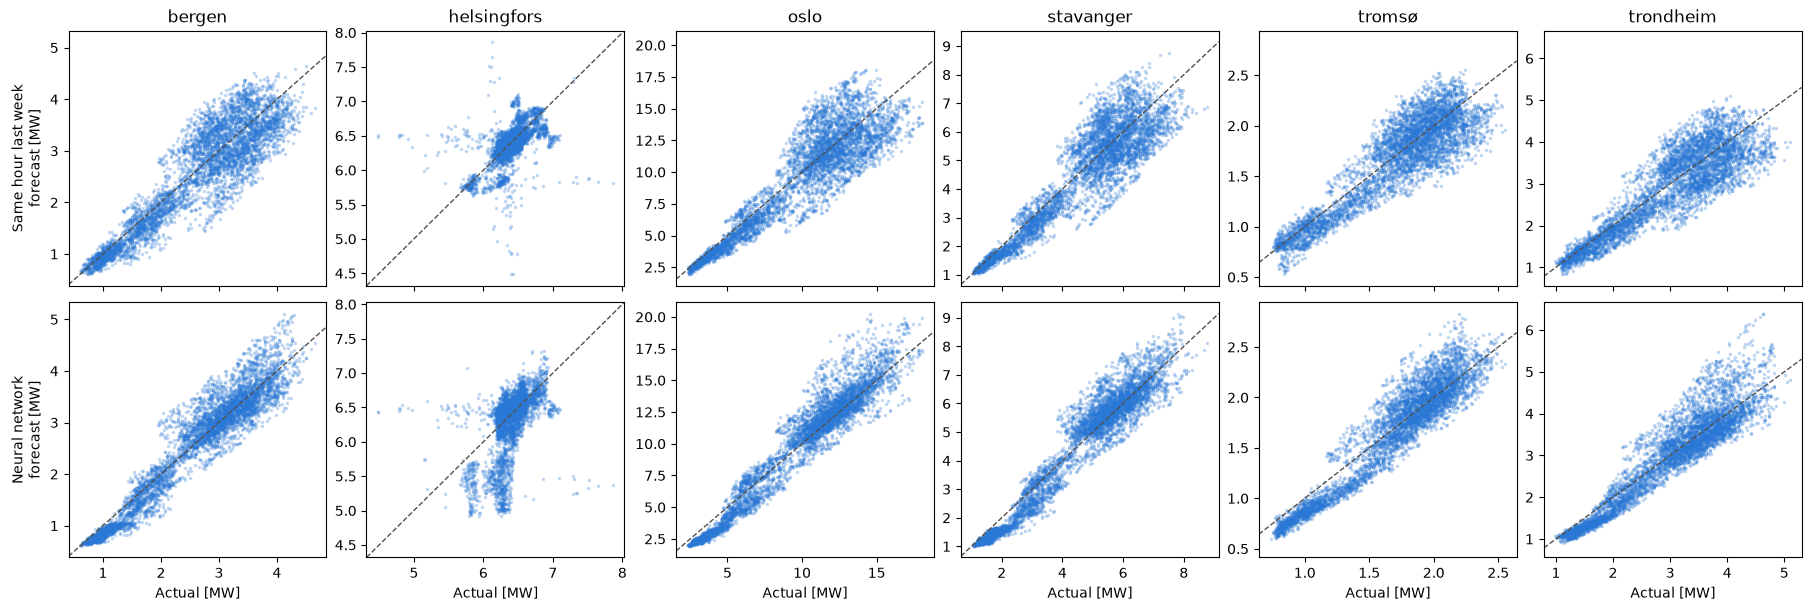

In [13]:
validator.plot_predicted_vs_actual_consumption()